# 第 2 天：Python 数据分析与质量看板

**目标**：先检查数据，再计算指标；按时间、设备、班次、批次、缺陷类型定位误报；解释结论及其边界。

输入：`data/raw/aoi_inspection.csv`（模拟数据，由 `scripts/generate_data.py` 生成）
输出：`data/processed/aoi_clean.csv` 和 `reports/dashboard/*.png`

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy import stats

sns.set_theme(style="whitegrid")

cwd = Path.cwd()
ROOT = next((folder.parent for folder in (cwd, *cwd.parents) if folder.name == "notebooks"), cwd)
RAW = ROOT / "data" / "raw" / "aoi_inspection.csv"
PROCESSED = ROOT / "data" / "processed"
DASHBOARD = ROOT / "reports" / "dashboard"
PROCESSED.mkdir(parents=True, exist_ok=True)
DASHBOARD.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.tight_layout()
    fig.savefig(DASHBOARD / name, dpi=150, bbox_inches="tight")

## 1. 先检查数据，而不是直接计算

In [2]:
df = pd.read_csv(RAW)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60514 entries, 0 to 60513
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   inspection_id     60514 non-null  str    
 1   product_id        60514 non-null  str    
 2   inspection_time   60514 non-null  str    
 3   line_id           60514 non-null  str    
 4   machine_id        60514 non-null  str    
 5   batch_id          60514 non-null  str    
 6   shift             60514 non-null  str    
 7   defect_type       60514 non-null  str    
 8   aoi_result        60514 non-null  str    
 9   reference_result  60228 non-null  str    
 10  aoi_score         60514 non-null  float64
 11  brightness        60237 non-null  float64
 12  contrast          60267 non-null  float64
dtypes: float64(3), str(10)
memory usage: 9.2 MB


In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
inspection_id,60514,60395,I000607,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,60514,59604,P000590,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
inspection_time,60514,59703,2026-10-10 19:40:45,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
line_id,60514,3,L02,20290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
machine_id,60514,6,M02,10221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
batch_id,60514,90,B011,732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shift,60514,3,night,20276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
defect_type,60514,5,none,55752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aoi_result,60514,2,OK,55783,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reference_result,60228,2,OK,59492,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df["inspection_time"] = pd.to_datetime(df["inspection_time"], errors="coerce")

by_inspection = df.drop_duplicates("inspection_id")
inspections_per_product = by_inspection.groupby("product_id").size()

checks = pd.Series(
    {
        "rows": len(df),
        "unparseable inspection_time": int(df["inspection_time"].isna().sum()),
        "duplicate inspection_id rows (dirty)": int(df.duplicated("inspection_id").sum()),
        "fully duplicated rows": int(df.duplicated().sum()),
        "distinct products": int(df["product_id"].nunique()),
        "products inspected more than once": int((inspections_per_product > 1).sum()),
        "missing reference_result": int(df["reference_result"].isna().sum()),
        "missing brightness": int(df["brightness"].isna().sum()),
        "missing contrast": int(df["contrast"].isna().sum()),
    },
    name="count",
)
checks.to_frame()

,count
rows,60514
unparseable inspection_time,0
duplicate inspection_id rows (dirty),119
fully duplicated rows,119
distinct products,59604
products inspected more than once,791
missing reference_result,286
missing brightness,277
missing contrast,247


逐条回答讲义里的检查问题：

- **一行代表什么？** 一次检测事件，不是一件产品。
- **`product_id` 重复合理吗？** 要看是哪些产品重复。下面验证：重复的产品首检是否都是 NG？
- **`inspection_id` 重复呢？** 同一个检测事件不该出现两次，这是脏数据，必须去重。
- **缺失是否集中？** 看缺失在设备、日期上的分布。

In [5]:
ordered = by_inspection.sort_values(["inspection_time", "inspection_id"]).copy()
ordered["seq"] = ordered.groupby("product_id").cumcount() + 1
multi = ordered[ordered.groupby("product_id")["inspection_id"].transform("size") > 1]

print("重复检测的产品，首检 AOI 结果分布：")
print(multi[multi["seq"] == 1]["aoi_result"].value_counts().to_string())

example_product = multi["product_id"].iloc[0]
multi[multi["product_id"] == example_product][
    [
        "inspection_id",
        "product_id",
        "inspection_time",
        "machine_id",
        "aoi_result",
        "aoi_score",
        "reference_result",
    ]
]

重复检测的产品，首检 AOI 结果分布：
aoi_result
NG    791


,inspection_id,product_id,inspection_time,machine_id,aoi_result,aoi_score,reference_result
225,I000226,P000226,2026-10-01 02:39:58,M05,NG,0.6865,OK
237,I000238,P000226,2026-10-01 02:47:46,M05,NG,0.6448,OK


重复的产品全部是 **AOI 首检报警后被复测**的产品，所以**不能简单按 `product_id` 去重**。
但统计误报时，同一件产品的复测不能重复计数，否则会放大误报（见第 3 节）。

In [6]:
missing_view = df.assign(
    missing_reference=df["reference_result"].isna(),
    missing_brightness=df["brightness"].isna(),
)
display(
    missing_view.groupby("machine_id")[["missing_reference", "missing_brightness"]]
    .mean()
    .style.format("{:.2%}")
)
display(
    missing_view.groupby(missing_view["inspection_time"].dt.date)["missing_reference"]
    .mean()
    .describe()
    .to_frame("daily missing_reference rate")
    .T.style.format("{:.2%}")
)

,missing_reference,missing_brightness
machine_id,,
M01,0.58%,0.46%
M02,0.50%,0.43%
M03,0.43%,0.50%
M04,0.41%,0.46%
M05,0.41%,0.45%
M06,0.51%,0.44%


,count,mean,std,min,25%,50%,75%,max
daily missing_reference rate,3000.00%,0.47%,0.17%,0.15%,0.36%,0.46%,0.57%,0.87%


缺失率在各设备间和各天之间基本一致（约 0.5%），看起来是随机缺失，不是某台设备的系统性问题。
真实数据中如果缺失集中在某台设备或某个时段，就要先排查数据链路。

## 2. 清洗并保存

- 按 `inspection_id` 去重
- 标记每件产品的**首检**（`is_first_pass`），统计误报时以首检为单位
- 缺失的 `brightness`/`contrast` 保留为 NaN，不在分析阶段随意填充（建模时再处理）

In [7]:
clean = (
    df.drop_duplicates("inspection_id")
    .sort_values(["inspection_time", "inspection_id"])
    .reset_index(drop=True)
)
clean["date"] = clean["inspection_time"].dt.normalize()
clean["hour"] = clean["inspection_time"].dt.hour
clean["inspection_seq"] = clean.groupby("product_id").cumcount() + 1
clean["is_first_pass"] = clean["inspection_seq"] == 1
clean["has_reference"] = clean["reference_result"].isin(["OK", "NG"])
clean["is_alarm"] = clean["aoi_result"] == "NG"
clean["is_actual_defect"] = clean["reference_result"] == "NG"
clean["is_actual_good"] = clean["reference_result"] == "OK"
clean["is_true_positive"] = clean["is_alarm"] & clean["is_actual_defect"]
clean["is_false_positive"] = clean["is_alarm"] & clean["is_actual_good"]
clean["is_miss"] = ~clean["is_alarm"] & clean["is_actual_defect"]

clean.to_csv(PROCESSED / "aoi_clean.csv", index=False)
print(f"saved {len(clean)} rows -> {PROCESSED / 'aoi_clean.csv'}")

first_pass = clean[clean["is_first_pass"]]
verified_first = first_pass[first_pass["has_reference"]]
verified_all = clean[clean["has_reference"]]


def rollup(frame, by):
    g = frame.groupby(by, observed=True).agg(
        inspections=("inspection_id", "size"),
        alarms=("is_alarm", "sum"),
        good=("is_actual_good", "sum"),
        defects=("is_actual_defect", "sum"),
        tp=("is_true_positive", "sum"),
        fp=("is_false_positive", "sum"),
        fn=("is_miss", "sum"),
    )
    g["alarm_rate"] = g["alarms"] / g["inspections"]
    g["fpr"] = g["fp"] / g["good"].replace(0, np.nan)
    g["recall"] = g["tp"] / g["defects"].replace(0, np.nan)
    g["fp_share_of_alarms"] = g["fp"] / g["alarms"].replace(0, np.nan)
    return g.reset_index()


fmt = {
    "alarm_rate": "{:.2%}",
    "fpr": "{:.2%}",
    "recall": "{:.2%}",
    "fp_share_of_alarms": "{:.1%}",
}

saved 60395 rows -> /Users/Phil/Workspace/Study/MQE/apple-mqe-interview/data/processed/aoi_clean.csv


## 3. 统计单位决定数字：首检 vs 全部检测事件

In [8]:
scope_table = pd.concat(
    [
        rollup(verified_first.assign(scope="First pass only (1 row per product)"), "scope"),
        rollup(verified_all.assign(scope="All inspection events (incl. retests)"), "scope"),
    ]
).set_index("scope")
scope_table.style.format(fmt)

,inspections,alarms,good,defects,tp,fp,fn,alarm_rate,fpr,recall,fp_share_of_alarms
scope,,,,,,,,,,,
First pass only (1 row per product),59323,3962,58713,610,579,3383,31,6.68%,5.76%,94.92%,85.4%
All inspection events (incl. retests),60109,4689,59375,734,703,3986,31,7.80%,6.71%,95.78%,85.0%


把复测也算进去，会让误报数量虚高、误报率偏离首检口径。**本分析统一用"每件产品的首检"作为统计单位。**

## 4. 现实情况：只有报警件被复判会怎样

In [9]:
alarmed = verified_first[verified_first["is_alarm"]]
confirmed_fp = int(alarmed["is_false_positive"].sum())
print(
    f"已复判报警 {len(alarmed)} 件，其中确认误报 {confirmed_fp} 件（{confirmed_fp / len(alarmed):.1%}）"
)
print("放行件没有参考判定 -> 无法计算漏检数、Recall、良品误报率")
print("（模拟数据里有全量参考，所以上面能算出真实 Recall；真实产线必须靠独立抽检来估计漏检）")

已复判报警 3962 件，其中确认误报 3383 件（85.4%）
放行件没有参考判定 -> 无法计算漏检数、Recall、良品误报率
（模拟数据里有全量参考，所以上面能算出真实 Recall；真实产线必须靠独立抽检来估计漏检）


这也是看板指标命名要写准确的原因：只能叫"**已复判报警中的误报占比**"，不能叫"全产线误报率"。

## 5. 全局指标

In [10]:
overall = rollup(verified_first.assign(scope="overall"), "scope").iloc[0]
overall_fpr = overall["fpr"]
overall_recall = overall["recall"]
overall_precision = overall["tp"] / overall["alarms"]
print(f"First-pass products with reference: {int(overall['inspections'])}")
print(f"TP={int(overall['tp'])}  FP={int(overall['fp'])}  FN={int(overall['fn'])}")
print(f"Recall={overall_recall:.2%}  FPR={overall_fpr:.2%}  Precision={overall_precision:.2%}")

First-pass products with reference: 59323
TP=579  FP=3383  FN=31
Recall=94.92%  FPR=5.76%  Precision=14.61%


## 6. 必做图表

### 图 1：每天 AOI 报警数量

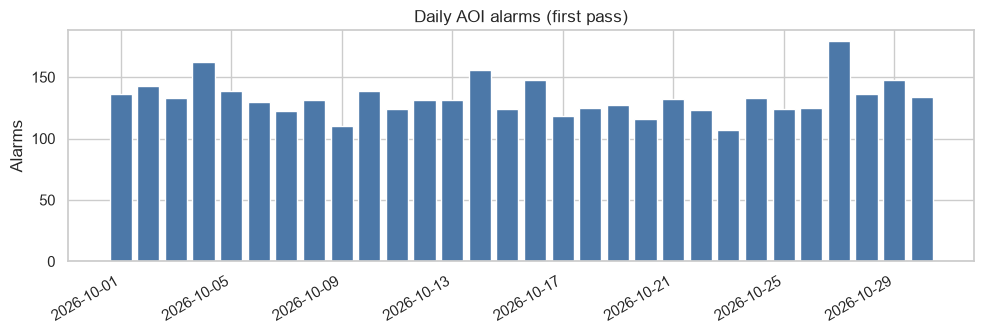

In [11]:
daily_alarms = first_pass.groupby("date").agg(
    inspections=("inspection_id", "size"), alarms=("is_alarm", "sum")
)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(daily_alarms.index, daily_alarms["alarms"], color="#4C78A8")
ax.set_title("Daily AOI alarms (first pass)")
ax.set_ylabel("Alarms")
fig.autofmt_xdate()
save(fig, "01_daily_alarms.png")

### 图 2：每天误报数量与误报率（标注误报率最高的 2 天）

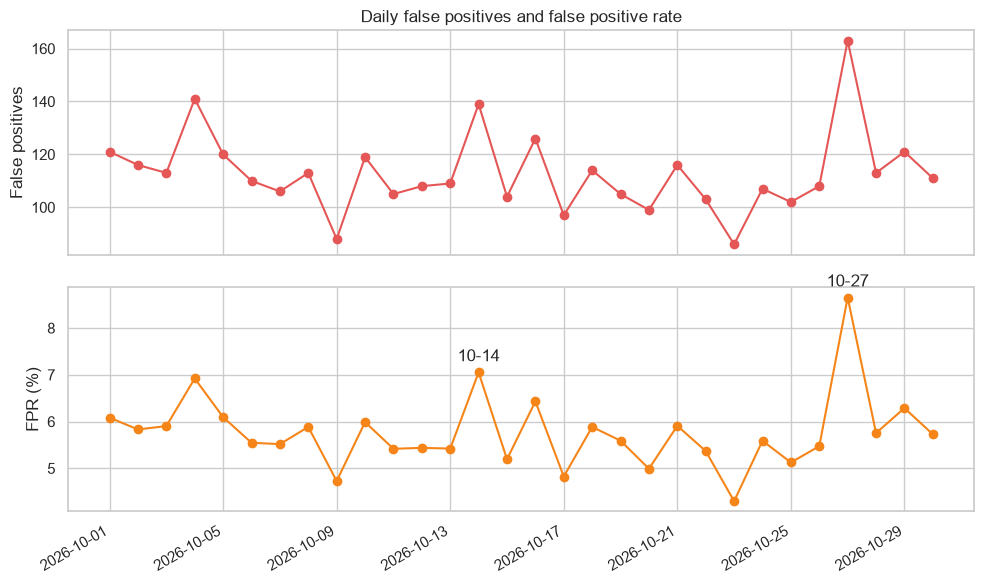

In [12]:
daily = rollup(verified_first, "date")
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(daily["date"], daily["fp"], marker="o", color="#E45756")
axes[0].set_ylabel("False positives")
axes[0].set_title("Daily false positives and false positive rate")
axes[1].plot(daily["date"], daily["fpr"] * 100, marker="o", color="#F58518")
axes[1].set_ylabel("FPR (%)")
for _, row in daily.nlargest(2, "fpr").iterrows():
    axes[1].annotate(
        row["date"].strftime("%m-%d"),
        (row["date"], row["fpr"] * 100),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
    )
fig.autofmt_xdate()
save(fig, "02_daily_false_positives.png")

### 图 3：各设备误报率对比

,machine_id,inspections,alarms,good,defects,tp,fp,fn,alarm_rate,fpr,recall,fp_share_of_alarms
0,M01,9686,652,9580,106,100,552,6,6.73%,5.76%,94.34%,84.7%
1,M02,10034,625,9952,82,77,548,5,6.23%,5.51%,93.90%,87.7%
2,M03,9961,712,9839,122,118,594,4,7.15%,6.04%,96.72%,83.4%
3,M04,9935,669,9848,87,81,588,6,6.73%,5.97%,93.10%,87.9%
4,M05,9857,647,9754,103,99,548,4,6.56%,5.62%,96.12%,84.7%
5,M06,9850,657,9740,110,104,553,6,6.67%,5.68%,94.55%,84.2%


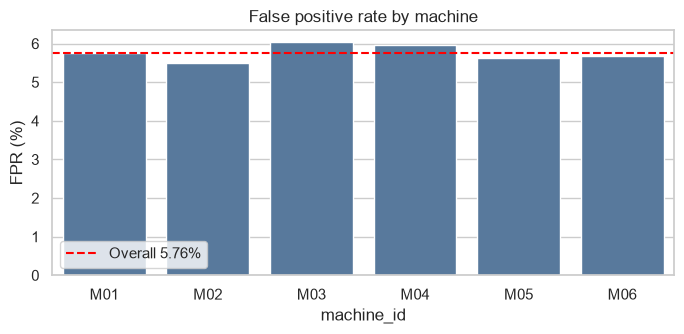

In [13]:
by_machine = rollup(verified_first, "machine_id")
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(data=by_machine, x="machine_id", y=by_machine["fpr"] * 100, color="#4C78A8", ax=ax)
ax.axhline(overall_fpr * 100, color="red", linestyle="--", label=f"Overall {overall_fpr:.2%}")
ax.set_ylabel("FPR (%)")
ax.set_title("False positive rate by machine")
ax.legend()
save(fig, "03_fpr_by_machine.png")
by_machine.style.format(fmt)

整体看六台设备差别很小，**按设备聚合会掩盖"某一天某台设备"的问题**。所以要再看设备 × 日期。

### 图 4：不同缺陷类型的报警数量（AOI 报出的类型）

reference_result,True defect,False positive,fp_share
defect_type,,,
crack,94,349,78.8%
dent,136,491,78.3%
scratch,248,1381,84.8%
stain,101,1162,92.0%


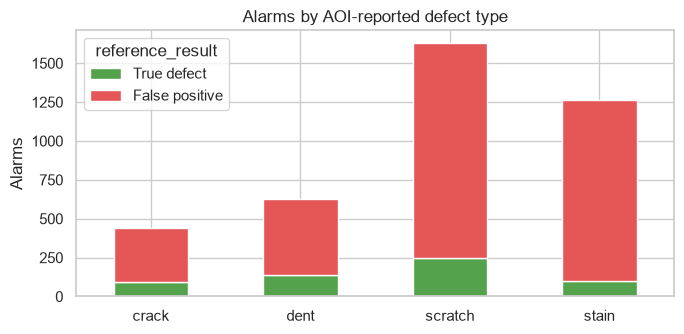

In [14]:
alarm_types = (
    verified_first[verified_first["is_alarm"]]
    .groupby(["defect_type", "reference_result"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={"NG": "True defect", "OK": "False positive"})
    .loc[:, ["True defect", "False positive"]]
)
fig, ax = plt.subplots(figsize=(7, 3.5))
alarm_types.plot(kind="bar", stacked=True, color=["#54A24B", "#E45756"], ax=ax)
ax.set_title("Alarms by AOI-reported defect type")
ax.set_ylabel("Alarms")
ax.set_xlabel("")
plt.setp(ax.get_xticklabels(), rotation=0)
save(fig, "04_alarms_by_defect_type.png")
alarm_types.assign(fp_share=lambda t: t["False positive"] / t.sum(axis=1)).style.format(
    {"fp_share": "{:.1%}"}
)

### 图 5：不同班次与批次的误报情况

,shift,inspections,alarms,good,defects,tp,fp,fn,alarm_rate,fpr,recall,fp_share_of_alarms
0,day,19752,1206,19545,207,198,1008,9,6.11%,5.16%,95.65%,83.6%
1,swing,19743,1224,19537,206,196,1028,10,6.20%,5.26%,95.15%,84.0%
2,night,19828,1532,19631,197,185,1347,12,7.73%,6.86%,93.91%,87.9%


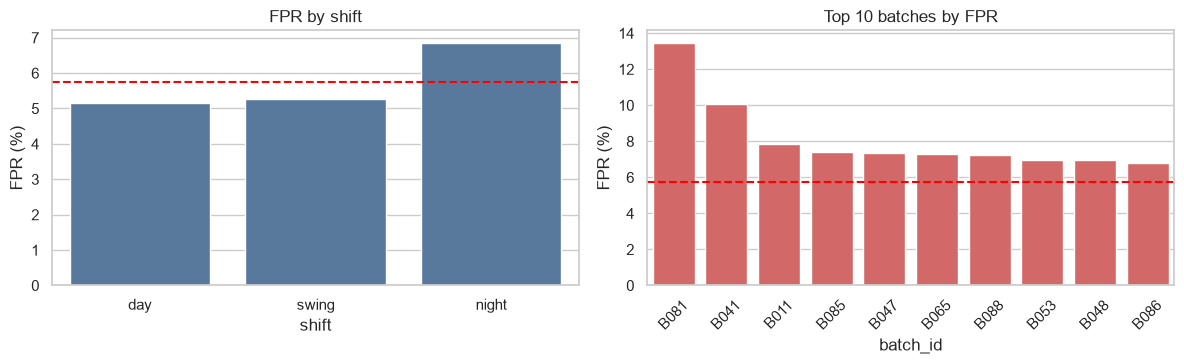

In [15]:
by_shift = (
    rollup(verified_first, "shift").set_index("shift").loc[["day", "swing", "night"]].reset_index()
)
by_batch = rollup(verified_first, "batch_id")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.barplot(data=by_shift, x="shift", y=by_shift["fpr"] * 100, color="#4C78A8", ax=axes[0])
axes[0].axhline(overall_fpr * 100, color="red", linestyle="--")
axes[0].set_ylabel("FPR (%)")
axes[0].set_title("FPR by shift")

top_batches = by_batch.nlargest(10, "fpr")
sns.barplot(data=top_batches, x="batch_id", y=top_batches["fpr"] * 100, color="#E45756", ax=axes[1])
axes[1].axhline(overall_fpr * 100, color="red", linestyle="--")
axes[1].set_ylabel("FPR (%)")
axes[1].set_title("Top 10 batches by FPR")
plt.setp(axes[1].get_xticklabels(), rotation=45)
save(fig, "05_fpr_by_shift_and_batch.png")
by_shift.style.format(fmt)

### 图 6：设备 × 日期的误报率热力图（定位异常）

,machine_id,date,inspections,alarms,good,defects,tp,fp,fn,alarm_rate,fpr,recall,fp_share_of_alarms
73,M03,2026-10-14 00:00:00,339,51,337,2,2,49,0,15.04%,14.54%,100.00%,96.1%
176,M06,2026-10-27 00:00:00,334,46,333,1,1,45,0,13.77%,13.51%,100.00%,97.8%
146,M05,2026-10-27 00:00:00,322,45,320,2,2,43,0,13.98%,13.44%,100.00%,95.6%
58,M02,2026-10-29 00:00:00,337,29,337,0,0,29,0,8.61%,8.61%,nan%,100.0%
63,M03,2026-10-04 00:00:00,373,34,370,3,3,31,0,9.12%,8.38%,100.00%,91.2%


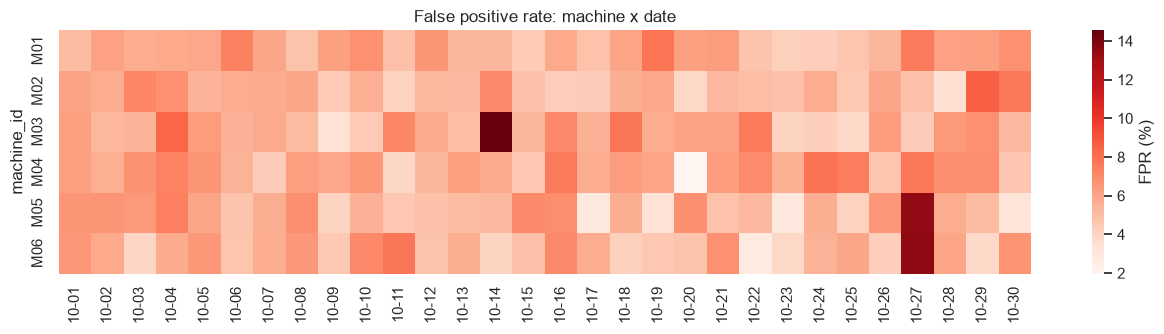

In [16]:
machine_day = rollup(verified_first, ["machine_id", "date"])
heat = machine_day.pivot(index="machine_id", columns="date", values="fpr") * 100
fig, ax = plt.subplots(figsize=(13, 3.5))
sns.heatmap(heat, cmap="Reds", cbar_kws={"label": "FPR (%)"}, ax=ax)
ax.set_xticklabels([d.strftime("%m-%d") for d in heat.columns], rotation=90)
ax.set_title("False positive rate: machine x date")
ax.set_xlabel("")
save(fig, "06_fpr_heatmap_machine_day.png")

machine_day.nlargest(5, "fpr").style.format(fmt)

## 7. 异常定位：误报率最高的"设备-日期"

先确认**检测数量**是否也变了，再看比例；然后按班次、时段拆分，并和**同批次其他设备**对比。

In [17]:
peak = machine_day.nlargest(1, "fpr").iloc[0]
target_machine, target_day = peak["machine_id"], peak["date"]
day_frame = verified_first[verified_first["date"] == target_day]
target_frame = day_frame[day_frame["machine_id"] == target_machine]
target_batches = target_frame["batch_id"].unique()
peer_frame = day_frame[
    day_frame["batch_id"].isin(target_batches) & (day_frame["machine_id"] != target_machine)
]
peer_machines = sorted(peer_frame["machine_id"].unique())
print(
    f"异常点：{target_machine} @ {target_day:%Y-%m-%d (%a)}，批次 {list(target_batches)}，同批次对照设备 {peer_machines}"
)

baseline_frame = verified_first[
    (verified_first["machine_id"] == target_machine) & (verified_first["date"] != target_day)
]
rollup(
    pd.concat(
        [
            target_frame.assign(group=f"{target_machine} on anomaly day"),
            peer_frame.assign(group=f"{'/'.join(peer_machines)} same batch same day"),
            baseline_frame.assign(group=f"{target_machine} other days"),
        ]
    ),
    "group",
).style.format(fmt)

异常点：M03 @ 2026-10-14 (Wed)，批次 ['B041']，同批次对照设备 ['M04']


,group,inspections,alarms,good,defects,tp,fp,fn,alarm_rate,fpr,recall,fp_share_of_alarms
0,M03 on anomaly day,339,51,337,2,2,49,0,15.04%,14.54%,100.00%,96.1%
1,M03 other days,9622,661,9502,120,116,545,4,6.87%,5.74%,96.67%,82.5%
2,M04 same batch same day,351,21,350,1,1,20,0,5.98%,5.71%,100.00%,95.2%


数量没有明显变化，但误报**比例**明显更高；同批次、同产线的另一台设备正常，说明不太像产品或批次问题，
更像这台设备自身的问题。下面检验这个差异是否可能只是随机波动。

In [18]:
peer_good = int(peer_frame["is_actual_good"].sum())
peer_fp = int(peer_frame["is_false_positive"].sum())
target_good = int(target_frame["is_actual_good"].sum())
target_fp = int(target_frame["is_false_positive"].sum())
_, fisher_p = stats.fisher_exact(
    [[target_fp, target_good - target_fp], [peer_fp, peer_good - peer_fp]]
)
print(
    f"{target_machine}: {target_fp}/{target_good} = {target_fp / target_good:.1%}  vs  "
    f"peer: {peer_fp}/{peer_good} = {peer_fp / peer_good:.1%}  (Fisher exact p = {fisher_p:.2e})"
)

M03: 49/337 = 14.5%  vs  peer: 20/350 = 5.7%  (Fisher exact p = 1.21e-04)


In [19]:
target_shift = (
    rollup(target_frame, "shift")
    .set_index("shift")
    .reindex(["night", "day", "swing"])
    .reset_index()
)
target_shift.style.format(fmt)

,shift,inspections,alarms,good,defects,tp,fp,fn,alarm_rate,fpr,recall,fp_share_of_alarms
0,night,121,10,120,1,1,9,0,8.26%,7.50%,100.00%,90.0%
1,day,106,12,105,1,1,11,0,11.32%,10.48%,100.00%,91.7%
2,swing,112,29,112,0,0,29,0,25.89%,25.89%,nan%,100.0%


异常集中在后半天，不是整天都高。再看 3 小时时段，并叠加亮度特征：

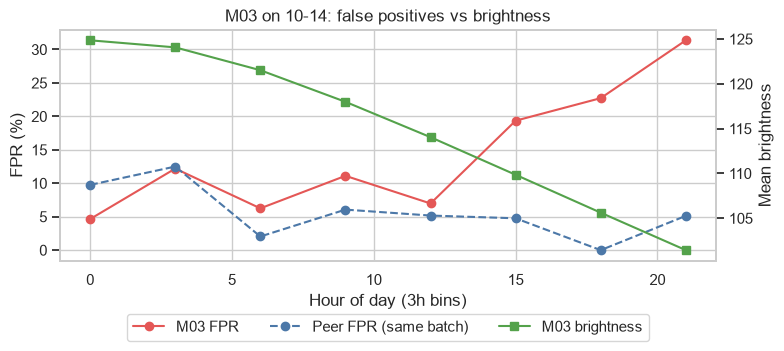

In [20]:
def by_time_bin(frame):
    return rollup(frame.assign(hour_bin=(frame["hour"] // 3) * 3), "hour_bin")


target_bins = by_time_bin(target_frame)
peer_bins = by_time_bin(peer_frame)
brightness_bins = target_frame.groupby((target_frame["hour"] // 3) * 3)["brightness"].mean()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(
    target_bins["hour_bin"],
    target_bins["fpr"] * 100,
    marker="o",
    color="#E45756",
    label=f"{target_machine} FPR",
)
ax.plot(
    peer_bins["hour_bin"],
    peer_bins["fpr"] * 100,
    marker="o",
    linestyle="--",
    color="#4C78A8",
    label="Peer FPR (same batch)",
)
ax.set_xlabel("Hour of day (3h bins)")
ax.set_ylabel("FPR (%)")
ax2 = ax.twinx()
ax2.plot(
    brightness_bins.index,
    brightness_bins.values,
    marker="s",
    color="#54A24B",
    label=f"{target_machine} brightness",
)
ax2.set_ylabel("Mean brightness")
ax2.grid(False)
lines = ax.get_legend_handles_labels()
lines2 = ax2.get_legend_handles_labels()
ax.legend(
    lines[0] + lines2[0],
    lines[1] + lines2[1],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3,
)
ax.set_title(f"{target_machine} on {target_day:%m-%d}: false positives vs brightness")
save(fig, "07_anomaly_drilldown.png")

In [21]:
brightness_compare = pd.DataFrame(
    {
        "anomaly day": target_frame["brightness"].describe(),
        "other days": baseline_frame["brightness"].describe(),
    }
).T[["count", "mean", "std", "min"]]
brightness_compare.style.format("{:.1f}")

,count,mean,std,min
anomaly day,338.0,114.8,9.5,93.2
other days,9573.0,124.0,4.0,108.4


**能得出什么、不能得出什么：**

- 数据只提供**线索**：该设备在当天后半段亮度持续下降，同时误报上升，和"光源衰减"的假设一致。
- **不能直接说"设备坏了"**。下一步要核对设备光源寿命、维护记录和参数变更，并做现场验证。

## 8. 第二个线索：是设备问题，还是批次/产线问题？

用二项分布的 z 值给各批次打分，再看被标出的批次里，是**单台设备**高还是**所有设备**都高。

In [22]:
p0 = overall_fpr
batch_scores = by_batch.assign(z=lambda t: (t["fpr"] - p0) / np.sqrt(p0 * (1 - p0) / t["good"]))
flagged = batch_scores[batch_scores["z"] > 4].sort_values("z", ascending=False)
display(
    flagged[["batch_id", "good", "fp", "fpr", "z"]].style.format({"fpr": "{:.2%}", "z": "{:.1f}"})
)

flagged_machine = rollup(
    verified_first[verified_first["batch_id"].isin(flagged["batch_id"])],
    ["batch_id", "machine_id"],
)
display(
    flagged_machine[["batch_id", "machine_id", "good", "fp", "fpr"]].style.format({"fpr": "{:.2%}"})
)

,batch_id,good,fp,fpr,z
80,B081,653,88,13.48%,8.5
40,B041,687,69,10.04%,4.8


,batch_id,machine_id,good,fp,fpr
0,B041,M03,337,49,14.54%
1,B041,M04,350,20,5.71%
2,B081,M05,320,43,13.44%
3,B081,M06,333,45,13.51%


In [23]:
glare_batch = (
    flagged[~flagged["batch_id"].isin(target_batches)]["batch_id"].iloc[0]
    if (~flagged["batch_id"].isin(target_batches)).any()
    else None
)
if glare_batch:
    glare_frame = verified_first[verified_first["batch_id"] == glare_batch]
    glare_line = glare_frame["line_id"].iloc[0]
    glare_date = glare_frame["date"].iloc[0]
    same_line_other_days = verified_first[
        (verified_first["line_id"] == glare_line) & (verified_first["date"] != glare_date)
    ]
    other_lines_same_day = verified_first[
        (verified_first["line_id"] != glare_line) & (verified_first["date"] == glare_date)
    ]
    features = pd.DataFrame(
        {
            f"{glare_batch} ({glare_line}, {glare_date:%m-%d})": glare_frame[
                ["brightness", "contrast"]
            ].mean(),
            f"{glare_line} other days": same_line_other_days[["brightness", "contrast"]].mean(),
            "Other lines same day": other_lines_same_day[["brightness", "contrast"]].mean(),
        }
    ).T
    display(features.style.format("{:.1f}"))

,brightness,contrast
"B081 (L03, 10-27)",135.5,17.0
L03 other days,125.3,20.6
Other lines same day,125.1,20.7


对比两个线索：

| | 异常设备 | 同批次其他设备 | 图像特征 | 倾向的方向 |
| --- | --- | --- | --- | --- |
| 线索 1 | 单台设备高 | 正常 | 亮度下降 | 设备/光源 |
| 线索 2 | 该批次所有设备都高 | 同样高 | 亮度偏高、对比度偏低 | 批次/来源（如表面反光） |

这就是"先拆维度，再同批次对比"的价值：同一个"误报升高"，可能是完全不同的根因，对应的处理动作也不同。

## 9. 班次差异

In [24]:
night = verified_first[verified_first["shift"] == "night"]
others = verified_first[verified_first["shift"] != "night"]
night_table = [
    [
        int(night["is_false_positive"].sum()),
        int(night["is_actual_good"].sum() - night["is_false_positive"].sum()),
    ],
    [
        int(others["is_false_positive"].sum()),
        int(others["is_actual_good"].sum() - others["is_false_positive"].sum()),
    ],
]
_, shift_p, _, _ = stats.chi2_contingency(night_table)
night_fpr = night["is_false_positive"].sum() / night["is_actual_good"].sum()
others_fpr = others["is_false_positive"].sum() / others["is_actual_good"].sum()
print(f"night FPR {night_fpr:.2%} vs other shifts {others_fpr:.2%} (chi-square p = {shift_p:.1e})")

night FPR 6.86% vs other shifts 5.21% (chi-square p = 6.2e-16)


夜班误报率统计上显著更高，但**显著不等于已知原因**：可能是温度、人员操作、物料批次或交接班时的设备状态，
需要结合现场信息才能下结论。

## 10. 按缺陷类型看召回（缺陷类型取自参考判定）

In [25]:
type_recall = rollup(verified_first[verified_first["is_actual_defect"]], "defect_type")
type_recall[["defect_type", "defects", "tp", "fn", "recall"]].style.format({"recall": "{:.1%}"})

,defect_type,defects,tp,fn,recall
0,crack,96,94,2,97.9%
1,dent,142,136,6,95.8%
2,scratch,265,248,17,93.6%
3,stain,107,101,6,94.4%


各类型召回率有差异，但每类的缺陷样本只有一百到两百多个，差异不宜过度解读。
流程上仍然必须**按缺陷类型拆开看**：整体 Recall 会掩盖个别类型的风险，
而且高严重度缺陷（如 crack）即使漏检很少也可能不可接受。

## 11. 分析小结（自动生成，数字随数据更新）

In [26]:
summary_md = f"""
**整体（首检，有参考判定）**：Recall {overall_recall:.1%}，良品误报率 {overall_fpr:.2%}，
Precision {overall_precision:.1%}，即人工看到的报警中约 {1 - overall_precision:.0%} 是误报。

**线索 1（设备）**：{target_machine} 在 {target_day:%Y-%m-%d} 良品误报率 {target_fp / target_good:.1%}，
同批次同线的 {"/".join(peer_machines)} 为 {peer_fp / peer_good:.1%}（Fisher p = {fisher_p:.1e}），
异常集中在后半天并伴随亮度下降。建议核查该设备光源状态与维护记录。

**线索 2（批次）**：{glare_batch or "n/a"} 整个批次的所有设备误报率都升高，亮度偏高、对比度偏低，
更像批次/来源（反光）问题，应联系工艺和来料质量确认。

**线索 3（班次）**：夜班误报率 {night_fpr:.2%} 高于其他班次 {others_fpr:.2%}，原因待现场确认。

**局限**：数据为模拟数据，且每条记录都有参考判定；真实产线通常只有报警件被复判，漏检需要独立抽检估计。
"""
display(Markdown(textwrap.dedent(summary_md)))


**整体（首检，有参考判定）**：Recall 94.9%，良品误报率 5.76%，
Precision 14.6%，即人工看到的报警中约 85% 是误报。

**线索 1（设备）**：M03 在 2026-10-14 良品误报率 14.5%，
同批次同线的 M04 为 5.7%（Fisher p = 1.2e-04），
异常集中在后半天并伴随亮度下降。建议核查该设备光源状态与维护记录。

**线索 2（批次）**：B081 整个批次的所有设备误报率都升高，亮度偏高、对比度偏低，
更像批次/来源（反光）问题，应联系工艺和来料质量确认。

**线索 3（班次）**：夜班误报率 6.86% 高于其他班次 5.21%，原因待现场确认。

**局限**：数据为模拟数据，且每条记录都有参考判定；真实产线通常只有报警件被复判，漏检需要独立抽检估计。
